# Aisle & Co. end to end: the ETL and the conversion model, day by day
MADT 8102 Capstone, Chapters 6 and 7: stress test of the whole pipeline

The ETL notebook tests the pipeline on its own. The ML notebook loads the final CRM once and then moves the
cutoff back in time. **Production works differently.** Couples write during the day, Sales replies, books and
closes. At 02:00 the ETL loads only what changed, and the model then works with whatever the warehouse holds
at that moment. This notebook runs exactly that cycle for **15 months, one day at a time**, then checks the
result against an independent full load. It also breaks the cycle on purpose, between the ETL and the model,
and puts it under load.

| Section | What it shows | Real-world question |
|---|---|---|
| 1 | The daily cycle, as Airflow runs it | What runs when, and what does each step wait for? |
| 2 | Bootstrap: the CRM as it was on 1 Oct 2025, first load, first model | How does a system go live on existing data? |
| 3 | 471 days replayed: CRM changes → incremental ETL → features → scores → monitor; training every Sunday | Does it hold up day after day? How long does a day take? |
| 4 | Correctness: the replay against a full load of the final CRM; the feature store against a recomputation | Is the result right, and does the model see only the past? |
| 5 | Failures between the ETL and the model: CRM down, crash, rerun, late data, a bad row, no model | Does the model ever score stale or wrong data? |
| 6 | Load: the CRM copied 15 and 40 times; ETL + model timed against the 2-minute target | How far does it scale? |
| 7 | Summary of every check | |

**What this run found and what was fixed.** Four gaps came up while building this notebook. All four are fixed in
the shared code and have their own tests:
1. *The model did not check that the day's ETL succeeded.* After a failed load, `python -m ml daily` would score
   yesterday's data without a word; only the Airflow task order prevented it. `features.require_fresh` now
   refuses (section 5).
2. *The Monday run froze the week that had just ended.* The Monday 02:00 run carries Sunday's changes, but the
   weekly workload froze every week before the Monday. A wedding booked on a Sunday therefore lost its first
   week of planning hours for good. The freeze now starts from the week of the run's last data day (section 4).
3. *A fixed inquiry came back without its messages.* A message whose inquiry is rejected goes to the dead letter
   as an orphan. When the inquiry is fixed in the CRM, the message itself has not changed, so its `UpdatedAt`
   never brought it back: the couple's chat was lost from the warehouse. Every run now reads the dead-letter
   orphans again (section 5.5).
4. *A new model never had to beat the one in production.* All 67 Sunday trainings were promoted: production had
   learnt from every inquiry up to 90 days before its own training date, and the gate looked for test inquiries
   after that date, so it never found any to compare on. Production is now replaced only when the new model is
   at least as good on at least 50 inquiries production never saw (counted once each, not once per scoring
   age); until then it is kept (section 4e).

In [1]:
import sys, time, logging
from dataclasses import replace
from datetime import date, datetime, timedelta
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
T0 = time.perf_counter()

ROOT = Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
from etl import db, pipeline
from etl.config import Config
from etl.__main__ import init_dw
from load_snapshot import load
from crm import crm_exec
from crosscheck import facts, compare_with_gold
from benchmark import small_change
import replay as R
from ml import features as F, train as T, score as S, monitor as M, forecast as FC

logging.basicConfig(level=logging.ERROR)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 110)
INK2, EDGE, BLUE, ORANGE, RED, GREEN = "#52514e", "#9a9893", "#2a78d6", "#eb6834", "#b03a2e", "#1a7f37"
ZONES = ROOT / "data" / "sim" / "zones_v3"
SLA = 120          # seconds: the designed latency of one nightly run

# Own databases, so the ETL and ML demos are not touched. Runs here are seconds apart instead of 24 hours,
# so the 5-minute re-read overlap (meant for late commits between two nightly runs) would re-read many
# earlier "days". It is set to 0 for the replay; section 5 shows that late data is still picked up.
cfg = replace(Config(), crm_dsn="dbname=aisleco_crm_e2e", dw_dsn="dbname=aisleco_dw_e2e",
              landing_dir=ROOT / "data" / "landing_e2e", overlap_seconds=0)

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
    print(("PASS  " if ok else "FAIL  ") + name + (f"  ({detail})" if detail else ""))
    assert ok, name

def dw(sql, params=None, c=None):
    c = c or cfg
    with db.connect(c.dw_dsn, c, autocommit=True) as conn:
        return pd.DataFrame(conn.execute(sql, params).fetchall())

def ml_daily(d, c=None):
    """The four daily model tasks of aisleco_daily_etl: ml_features -> ml_score -> ml_monitor -> ml_forecast."""
    c = c or cfg
    with db.connect(c.dw_dsn, c) as conn:
        n = F.materialise(conn, d); s = S.score(conn, d); m = M.monitor(conn, d)
        FC.forecast(conn, d); FC.monitor(conn, d); conn.commit()
    return n, s, m

## 1. The daily cycle

| When (Bangkok) | Airflow task | Code | Waits for |
|---|---|---|---|
| During the day | (the CRM application) | Couples write, Sales replies, consults, quotes, books, closes | |
| 02:00 | `extract` … `finish` (11 steps) | `etl.pipeline.run(cfg, D, "incremental")` | |
| after `finish` | `ml_features` | `features.materialise(D)` | the ETL run for D succeeded |
| | `ml_score` | `score.score(D)`: the follow-up list | `ml_features` |
| | `ml_monitor` | `monitor.monitor(D)`: drift, live AUC, alerts | `ml_score` |
| | `ml_forecast` | `forecast.forecast(D)`, `forecast.monitor(D)`: next 6 months against capacity | `ml_monitor` |
| Sunday 04:00 | `aisleco_weekly_train` | `train.train(D)`, `forecast.train(D)`: train, gate, register | the ETL run for D succeeded |

The run for day D carries the CRM's changes up to midnight before D. The replay below gives the CRM one day of
changes at a time and runs these steps in this order.

**How the CRM is replayed.** The simulated CRM exists only as its final state (15 Jan 2027). `scripts/replay.py`
rebuilds the CRM as it was at the start of any day from the timestamps it records. An inquiry exists from its
`InquiryDate`, it is `Contacted` from `ContactedDate` and `Quoted` from `QuotedDate`, and it is closed at
`ClosedDate`. A message exists from `SentAt` and a booking from its `CreatedDate`, and its team is planned at
booking. Each day's difference is written into the CRM as inserts and updates, so the CDC trigger stamps
`UpdatedAt` just as it would for the real application. One assumption: the CRM records no date for a
cancellation, so a cancelled wedding is taken to be cancelled halfway between its booking and its date.

## 2. Bootstrap: going live on 1 Oct 2025

The CRM already holds 21 months of history when the system starts. The first night runs a full load and trains
the first model on what was known that day.

In [2]:
fr = R.frames(ZONES)
assert R.matches_snapshot(fr, R.state(fr, date(2027, 1, 16))) == []      # the rewind rules reproduce the final CRM exactly
D0 = date(2025, 10, 1)
t = time.perf_counter()
prev = R.bootstrap(cfg, fr, D0)
init_dw(cfg, drop=True)
run0 = pipeline.run(cfg, D0, "full")
with db.connect(cfg.dw_dsn, cfg) as c:
    r0 = T.train(c, D0); c.commit()
print(f"go-live in {time.perf_counter() - t:.1f} s: full ETL run {run0}; model v{r0['version']} ({r0['algorithm']}) "
      f"{r0['status']}, test AUC {r0['test']['auc']} vs baseline {r0['baseline']['auc']}")
pd.DataFrame({"in the CRM on 1 Oct 2025": {t: len(v) for t, v in prev.items()},
              "in the final CRM (15 Jan 2027)": {t: len(fr[t]) for t in prev}})

warehouse aisleco_dw_e2e created (DW v7) with 27 data-quality rules


go-live in 1.7 s: full ETL run 1; model v1 (logistic regression) production, test AUC 0.798 vs baseline 0.728


,in the CRM on 1 Oct 2025,in the final CRM (15 Jan 2027)
Customer,1152,1929
CustomerChannelAccount,940,1614
ChatMessage,13090,22432
Inquiry,1136,1905
Event,187,297
EventEmployeeAssignment,657,1040


## 3. Daily replay: 2 Oct 2025 to 15 Jan 2027

Every day: the CRM receives the day's changes, the incremental ETL runs, then the three model tasks run. On
Sundays the weekly training runs after them. Each step is timed. This is the long cell (about 3 to 4 minutes).

In [3]:
days = pd.date_range(D0 + timedelta(days=1), date(2027, 1, 15)).date
log = []
for d in days:
    t0 = time.perf_counter()
    cur = R.state(fr, d); n = R.apply(cfg, cur, prev); prev = cur
    t1 = time.perf_counter()
    run_id = pipeline.run(cfg, d, "incremental")
    t2 = time.perf_counter()
    n_feat, n_scored, mon = ml_daily(d)
    t3 = time.perf_counter()
    trained = None
    if d.weekday() == 6:
        with db.connect(cfg.dw_dsn, cfg) as c:
            trained = T.train(c, d); c.commit()
            try:
                FC.train(c, d); c.commit()
            except ValueError:            # under a year of bookings before Feb 2026: no demand backtest yet
                c.rollback()
    t4 = time.perf_counter()
    log.append({"day": d, "crm_changes": sum(n.values()), "etl_s": t2 - t1, "ml_s": t3 - t2,
                "train_s": t4 - t3 if trained else np.nan, "run": run_id, "open": n_feat, "scored": n_scored,
                "alerts": sum(st == "alert" for _, _, st, _ in mon),
                "model": f"v{trained['version']} {trained['status']}" if trained else ""})
log = pd.DataFrame(log)
print(f"{len(log)} days replayed: {log.crm_changes.sum():,} CRM changes, {len(log)} ETL runs, "
      f"{(log.model != '').sum()} weekly trainings ({log.model.str.endswith('production').sum()} promoted, "
      f"{log.model.str.endswith('rejected').sum()} rejected)")
print(f"nightly ETL + model: median {(log.etl_s + log.ml_s).median():.2f} s, max {(log.etl_s + log.ml_s).max():.2f} s "
      f"(target {SLA} s); Sunday training: max {log.train_s.max():.2f} s")
check("every nightly run succeeded", dw('SELECT count(*) AS n FROM etl."Run" WHERE "Status" <> \'success\'').n[0] == 0,
      f"{len(log) + 1} runs")
check("every night inside the 2-minute target", ((log.etl_s + log.ml_s) < SLA).all())
log[log.model != ""].tail(5)

471 days replayed: 13,986 CRM changes, 471 ETL runs, 67 weekly trainings (9 promoted, 58 rejected)
nightly ETL + model: median 0.33 s, max 0.55 s (target 120 s); Sunday training: max 1.83 s
PASS  every nightly run succeeded  (472 runs)
PASS  every night inside the 2-minute target


,day,crm_changes,etl_s,ml_s,train_s,run,open,scored,alerts,model
437,2026-12-13,44,0.355547,0.103656,1.550209,439,37,37,0,v109 rejected
444,2026-12-20,38,0.283946,0.091187,1.622639,446,32,32,0,v111 rejected
451,2026-12-27,14,0.293904,0.086100,1.578910,453,35,35,0,v113 rejected
458,2027-01-03,12,0.286116,0.080366,1.572645,460,32,32,1,v115 rejected
465,2027-01-10,1,0.362436,0.089836,1.466121,467,26,26,1,v117 rejected


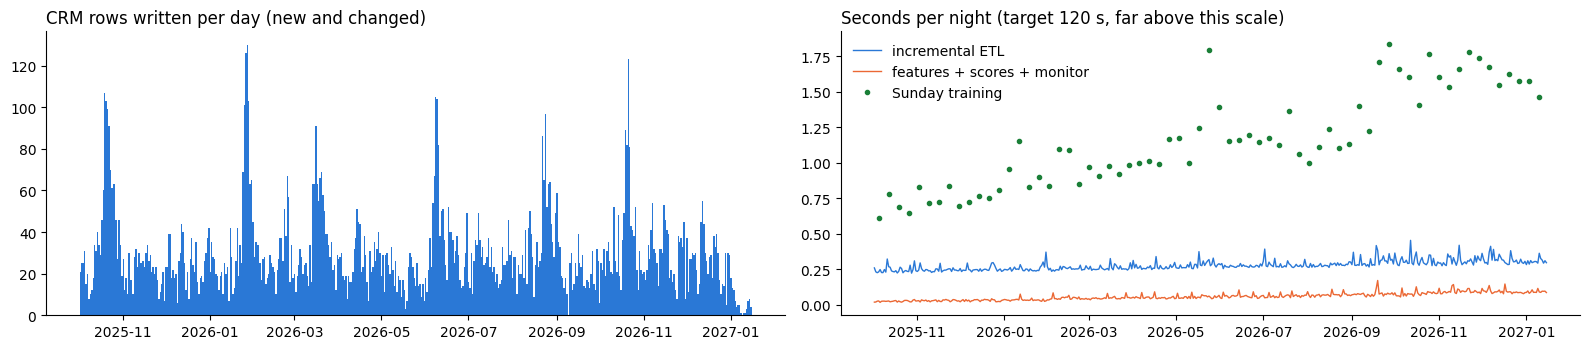

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 3.6))
w = log.set_index(pd.to_datetime(log.day))
ax[0].bar(w.index, w.crm_changes, color=BLUE, width=1)
ax[0].set_title("CRM rows written per day (new and changed)", loc="left")
ax[1].plot(w.index, w.etl_s, color=BLUE, lw=1, label="incremental ETL")
ax[1].plot(w.index, w.ml_s, color=ORANGE, lw=1, label="features + scores + monitor")
ax[1].plot(w.index, w.train_s, "o", color=GREEN, ms=3, label="Sunday training")
ax[1].set_title(f"Seconds per night (target {SLA} s, far above this scale)", loc="left"); ax[1].legend(frameon=False)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Correctness

The reference is an independent **full load of the final CRM** (`load_snapshot`, `aisleco_*_e2e_ref`). After 471
incremental runs the replayed warehouse should hold the same data. Where it may not, that is a designed
difference, and it is checked as one.

In [5]:
ref = replace(cfg, crm_dsn="dbname=aisleco_crm_e2e_ref", dw_dsn="dbname=aisleco_dw_e2e_ref",
              landing_dir=ROOT / "data" / "landing_e2e_ref")
load(ZONES, 1, ref); init_dw(ref, drop=True); pipeline.run(ref, date(2027, 1, 15), "full")

def crm_tables(c):
    with db.connect(c.crm_dsn, c) as conn:
        return {t: pd.DataFrame(conn.execute(f'SELECT * FROM {s}."{t}" ORDER BY "{k}"').fetchall()).drop(columns="UpdatedAt")
                for s, t, k in R.TABLES}
a, b = crm_tables(cfg), crm_tables(ref)
check("4a  CRM after 471 days of changes equals the final CRM", all(a[t].equals(b[t]) for t in a),
      ", ".join(f"{t} {len(a[t]):,}" for t in a))

rep, full = facts(cfg), facts(ref)
for k in ["FactInquiry", "FactEventBooking"]:
    check(f"4b  {k}: incremental = full load", rep[k].astype(str).equals(full[k].astype(str)), f"{len(rep[k]):,} rows")

warehouse aisleco_dw_e2e_ref created (DW v7) with 27 data-quality rules


PASS  4a  CRM after 471 days of changes equals the final CRM  (Customer 1,929, CustomerChannelAccount 1,614, Inquiry 1,905, ChatMessage 22,432, Event 297, EventEmployeeAssignment 1,040)
PASS  4b  FactInquiry: incremental = full load  (1,905 rows)
PASS  4b  FactEventBooking: incremental = full load  (297 rows)


**The weekly workload is the one designed difference.** Once a week has ended it is frozen: it keeps the hours
that were planned while it ran (Section 6, "late change"). A wedding cancelled later therefore still shows its
planning hours in the weeks before the cancellation. A full load built from the final CRM never saw those hours.
The check below allows a difference only in that case. The replay must have *more* hours, in a week that started
before the cancellation of a wedding that employee was assigned to, and each such case must have been reported
as a late change.

This is also the check that found the Monday bug. Before the fix, 22 employee-weeks had *fewer* hours in the
replay than in the full load: the planning hours of weddings booked on a Sunday, frozen by the Monday run before
it wrote them.

In [6]:
x, y = rep["FactEmployeeWeeklyWorkload"], full["FactEmployeeWeeklyWorkload"]
check("4b  FactEmployeeWeeklyWorkload: same employee-weeks", x.index.equals(y.index), f"{len(x):,} rows")
num = ["PlanningHours", "EventDayHours", "TotalAssignedHours", "ActiveEvents"]
dx = x[num].astype(float) - y[num].astype(float)
diff = dx[(dx.abs() > 0.001).any(axis=1)].reset_index()
diff["week"] = pd.to_datetime(diff.WeekStartDateKey.astype(str))
canc = fr["EventEmployeeAssignment"].assign(EmployeeID=lambda t: t.EmployeeID.astype(int),
                                            CancelAt=fr["_t"]["EventEmployeeAssignment"].CancelAt).dropna(subset=["CancelAt"])
canc = canc.merge(fr["Event"][["EventID", "EventDate"]], on="EventID").assign(EventDate=lambda t: pd.to_datetime(t.EventDate))
explained = diff.apply(lambda r: ((canc.EmployeeID == r.EmployeeID) & (canc.CancelAt > r.week)
                                  & (canc.EventDate >= r.week)).any(), axis=1)
last_cancel_week = canc.CancelAt.max().to_period("W-SUN").start_time
late = dw('''SELECT count(*) AS n FROM etl."Alert" WHERE "Message" LIKE '%%late change%%' ''').n[0]
check("4b  workload: the replay never has fewer hours than the full load", (diff[num] >= -0.001).all().all() if len(diff) else True)
check("4b  workload: every difference is a week frozen before a cancellation of that employee's wedding",
      explained.all(), f"{len(diff)} employee-weeks, {canc.EventID.nunique()} cancelled weddings")
check("4b  workload: identical from the week of the last cancellation on", (diff.week < last_cancel_week).all())
check("4b  workload: the frozen cancellations were reported as late changes", late > 0, f"{late} alerts")

checks_n, fails = compare_with_gold(ZONES, cfg)
other = [f for f in fails if not f.startswith("FactEmployeeWeeklyWorkload")]
check("4b  source-to-target vs the simulator's Gold zone: only the frozen weeks differ", not other,
      f"{checks_n:,} values compared")

PASS  4b  FactEmployeeWeeklyWorkload: same employee-weeks  (2,320 rows)
PASS  4b  workload: the replay never has fewer hours than the full load
PASS  4b  workload: every difference is a week frozen before a cancellation of that employee's wedding  (147 employee-weeks, 11 cancelled weddings)
PASS  4b  workload: identical from the week of the last cancellation on
PASS  4b  workload: the frozen cancellations were reported as late changes  (8 alerts)
PASS  4b  source-to-target vs the simulator's Gold zone: only the frozen weeks differ  (76,770 values compared)


**The feature store sees only the past.** Each night `ml_features` stored the features of the open inquiries while
the warehouse held data only up to that night. If the features depended on load order, or picked up anything
dated after the cutoff, recomputing them now from the complete warehouse would give different values. Every one
of the stored rows is recomputed.

In [7]:
with db.connect(cfg.dw_dsn, cfg) as c:
    stored = pd.DataFrame(c.execute('SELECT * FROM feature."InquiryFeatures"').fetchall())
    again = F.compute(c, stored.InquiryID.tolist(), [t.to_pydatetime() for t in pd.to_datetime(stored.AsOf)])
for col in F.NUM:
    stored[col] = pd.to_numeric(stored[col], errors="coerce").astype(float)
key = ["InquiryID", "AsOf"]
s1, s2 = stored.sort_values(key).reset_index(drop=True), again.sort_values(key).reset_index(drop=True)
check("4c  stored nightly features = recomputed point in time", s1.astype(str).equals(s2.astype(str)),
      f"{len(s1):,} rows over {stored.AsOf.nunique()} nights")

# open on day D = arrived before D and not closed before D (outcomes from the final warehouse)
sc = dw('SELECT "InquiryID", "AsOfDate", "Version" FROM ml."InquiryScore"')
lab = dw('SELECT "InquiryID", "ClosedAt" FROM feature."InquiryLabel"').set_index("InquiryID").ClosedAt
inq = dw('SELECT "InquiryID", "InquiryDate" FROM stg."Inquiry"')
expected = sum(((inq.InquiryDate < pd.Timestamp(d)) & ~(inq.InquiryID.map(lab) < pd.Timestamp(d))).sum() for d in log.day)
closed_scored = (sc.InquiryID.map(lab) < pd.to_datetime(sc.AsOfDate)).sum()
check("4d  every night scored exactly the inquiries open that night", len(sc) == expected == log.scored.sum(),
      f"{len(sc):,} scores")
check("4d  no closed inquiry was ever scored", closed_scored == 0)

reg = dw('SELECT "Version", "AsOfDate", "Status", "Decision" FROM ml."ModelVersion" WHERE "Model" = \'conversion\' ORDER BY 1')
promoted = reg[reg.Status.isin(["production", "retired"])]
expect = sc.AsOfDate.map(lambda d: promoted.Version[promoted.AsOfDate < d].max())
check("4e  exactly one production model", (reg.Status == "production").sum() == 1, f"{len(reg)} versions registered")
check("4e  each night scored with the model in production that night", (sc.Version == expect).all())
compared = promoted.Decision.iloc[1:].str.contains("vs production v")
check("4e  every replacement of production was compared with it", compared.all() and len(promoted) > 1,
      f"{len(promoted)} models promoted of {len(reg)} trained")

dm = dw('SELECT "Version", "AsOfDate", "Status" FROM ml."ModelVersion" WHERE "Model" = \'demand\' ORDER BY 1')
fcn = dw('SELECT "AsOfDate", count(*) AS months FROM ml."DemandForecast" GROUP BY 1')
nights = [d for d in log.day if d > dm.AsOfDate.min()]
check("4f  demand forecast: one production version, 6 months forecast every night after the first training",
      (dm.Status == "production").sum() == 1 and set(fcn.AsOfDate) >= set(nights) and (fcn.months == 6).all(),
      f"{len(dm)} versions from {dm.AsOfDate.min()}, {len(fcn)} nights forecast")
reg.Status.value_counts().to_frame("versions")

PASS  4c  stored nightly features = recomputed point in time  (22,796 rows over 471 nights)
PASS  4d  every night scored exactly the inquiries open that night  (22,796 scores)
PASS  4d  no closed inquiry was ever scored


PASS  4e  exactly one production model  (68 versions registered)
PASS  4e  each night scored with the model in production that night
PASS  4e  every replacement of production was compared with it  (10 models promoted of 68 trained)
PASS  4f  demand forecast: one production version, 6 months forecast every night after the first training  (50 versions from 2026-02-01, 348 nights forecast)


,versions
Status,
rejected,58
retired,9
production,1


In [8]:
# the showcase page (scripts/build_showcase.py) shows the warehouse as it is now, before section 5 adds test rows
import json
from build_showcase import snapshot
(ROOT / "docs" / "showcase").mkdir(parents=True, exist_ok=True)
(ROOT / "docs" / "showcase" / "snapshot.json").write_text(json.dumps(snapshot(cfg), separators=(",", ":")))
print("saved docs/showcase/snapshot.json (the warehouse on 15 Jan 2027)")

saved docs/showcase/snapshot.json (the warehouse on 15 Jan 2027)


## 5. Failures between the ETL and the model

The replay continues past 15 Jan 2027, one problem per day. The question each time: does the model ever
score data the warehouse does not have, and does the next good night repair everything?

In [9]:
inq_id = int(dw('''SELECT f."InquiryID" FROM feature."InquiryFeatures" f JOIN stg."Inquiry" i USING ("InquiryID")
                   WHERE f."AsOf" = '2027-01-15' AND f."HasChat" = 1 AND i."ConsultationDate" IS NULL ORDER BY f."AgeDays" LIMIT 1''').iloc[0, 0])
with db.connect(cfg.crm_dsn, cfg) as c:      # the couple's chat account, from the CRM
    acct = c.execute('SELECT "CustomerAccountID" FROM transaction."ChatMessage" WHERE "InquiryID" = %s LIMIT 1', (inq_id,)).fetchone()["CustomerAccountID"]
def feat(d, col):
    with db.connect(cfg.dw_dsn, cfg) as c:
        return F.stored(c, d).set_index("InquiryID")[col].get(inq_id)
msgs = lambda d: feat(d, "CoupleMsgs")
def chat(mid, sent):
    crm_exec(f'''INSERT INTO transaction."ChatMessage"("ChatMessageID","CustomerAccountID","InquiryID","PlatformMessageID",
                 "SentAt","Direction","SenderType") VALUES ({mid},{acct},{inq_id},'E2E-{mid}','{sent}','In','Customer')''', cfg)
print(f"followed inquiry: {inq_id}, couple messages stored on 15 Jan: {msgs(date(2027, 1, 15)):.0f}")

# --- 5.1 the CRM is unreachable on the night of 16 Jan ------------------------------------------
chat(9_000_001, "2027-01-15 20:00")
down = replace(cfg, crm_dsn="host=127.0.0.1 port=1 dbname=aisleco_crm_e2e", connect_retries=2, retry_base_seconds=0.2)
D16, D17 = date(2027, 1, 16), date(2027, 1, 17)
try:
    pipeline.run(down, D16); etl_failed = False
except ConnectionError as e:
    etl_failed = True; print("ETL 16 Jan:", e)
try:
    ml_daily(D16); refused = False
except F.StaleWarehouse as e:
    refused = True; print("model 16 Jan:", e)
check("5.1 CRM down: the ETL fails and the model refuses to score stale data", etl_failed and refused)
check("5.1 CRM down: nothing scored for 16 Jan", dw('SELECT count(*) AS n FROM ml."InquiryScore" WHERE "AsOfDate" = %s', (D16,)).n[0] == 0)
pipeline.run(cfg, D16); ml_daily(D16)          # the operator reruns the failed night once the CRM is back
pipeline.run(cfg, D17); ml_daily(D17)
check("5.1 after the rerun: 16 Jan scored, and the message of 15 Jan is in its features",
      msgs(D16) == msgs(date(2027, 1, 15)) + 1, f"couple messages {msgs(date(2027, 1, 15)):.0f} -> {msgs(D16):.0f}")

followed inquiry: 1905, couple messages stored on 15 Jan: 8


ERROR:etl:ALERT [error] run 473: step extract failed: could not connect to CRM after 2 attempts: connection failed: connection to server at "127.0.0.1", port 1 failed: could not receive data from server: Connection refused


ETL 16 Jan: could not connect to CRM after 2 attempts: connection failed: connection to server at "127.0.0.1", port 1 failed: could not receive data from server: Connection refused
model 16 Jan: warehouse loaded only to 2027-01-15: no successful ETL run as of 2027-01-16, nothing done
PASS  5.1 CRM down: the ETL fails and the model refuses to score stale data
PASS  5.1 CRM down: nothing scored for 16 Jan


PASS  5.1 after the rerun: 16 Jan scored, and the message of 15 Jan is in its features  (couple messages 8 -> 9)


In [10]:
# --- 5.2 a crash in the middle of the load on 18 Jan, then resume --------------------------------
D18 = date(2027, 1, 18)
crm_exec(f'UPDATE transaction."Inquiry" SET "ConsultationDate" = \'2027-01-17 15:00\' WHERE "InquiryID" = {inq_id}', cfg)
try:
    pipeline.run(replace(cfg, fail_at="fact_inquiry"), D18)
except RuntimeError as e:
    print("ETL 18 Jan:", e)
crashed = int(dw('SELECT max("RunID") AS r FROM etl."Run"').r[0])
try:
    ml_daily(D18); refused = False
except F.StaleWarehouse:
    refused = True
check("5.2 crash mid-load: the model waits for the run to finish", refused)
pipeline.resume(cfg, crashed); ml_daily(D18)
consulted = feat(D18, "Consulted")
check("5.2 after resume: the consultation of 17 Jan is in the 18 Jan features and scored", consulted == 1)

# --- 5.3 the same night runs twice (an Airflow retry, an operator's mistake) ---------------------
before = (facts(cfg), dw('SELECT * FROM feature."InquiryFeatures" WHERE "AsOf" = %s ORDER BY 1', (D18,)),
          dw('SELECT * FROM ml."InquiryScore" WHERE "AsOfDate" = %s ORDER BY 1', (D18,)))
pipeline.run(cfg, D18); ml_daily(D18)
after = (facts(cfg), dw('SELECT * FROM feature."InquiryFeatures" WHERE "AsOf" = %s ORDER BY 1', (D18,)),
         dw('SELECT * FROM ml."InquiryScore" WHERE "AsOfDate" = %s ORDER BY 1', (D18,)))
check("5.3 rerun of the same night: warehouse, features and scores unchanged",
      all(before[0][k].astype(str).equals(after[0][k].astype(str)) for k in before[0])
      and before[1].equals(after[1]) and before[2].equals(after[2]), f"{len(after[2])} scores")

ERROR:etl:ALERT [error] run 476: step fact_inquiry failed: injected failure in step fact_inquiry (ETL_FAIL_AT)


ETL 18 Jan: injected failure in step fact_inquiry (ETL_FAIL_AT)
PASS  5.2 crash mid-load: the model waits for the run to finish


PASS  5.2 after resume: the consultation of 17 Jan is in the 18 Jan features and scored


PASS  5.3 rerun of the same night: warehouse, features and scores unchanged  (20 scores)


In [11]:
# --- 5.4 late data: a message of 16 Jan reaches the CRM only on 18 Jan (a webhook backlog) -------
D19 = date(2027, 1, 19)
chat(9_000_002, "2027-01-16 09:00")
pipeline.run(cfg, D19); ml_daily(D19)
with db.connect(cfg.dw_dsn, cfg) as c:
    now_for_18 = F.compute(c, [inq_id], [datetime(2027, 1, 18)]).CoupleMsgs.iloc[0]
check("5.4 late data: loaded on 19 Jan, although its timestamp is older than the last run", msgs(D19) == msgs(D18) + 1)
check("5.4 late data: the stored 18 Jan features keep what was known that night",
      msgs(D18) == now_for_18 - 1, f"stored {msgs(D18):.0f}, recomputed now {now_for_18:.0f}")
print("This is why the offline store keeps every night's features: they record what the model actually saw. "
      "A recomputation sees the late message and would rewrite history.")

PASS  5.4 late data: loaded on 19 Jan, although its timestamp is older than the last run
PASS  5.4 late data: the stored 18 Jan features keep what was known that night  (stored 9, recomputed now 10)
This is why the offline store keeps every night's features: they record what the model actually saw. A recomputation sees the late message and would rewrite history.


In [12]:
# --- 5.5 a bad row: a new inquiry with a status the CRM should not allow ---------------------------
D20, D21 = date(2027, 1, 20), date(2027, 1, 21)
crm_exec('''INSERT INTO master."Customer"("CustomerID") VALUES (990001);
            INSERT INTO master."CustomerChannelAccount"("CustomerAccountID","CustomerID","Platform","ExternalUserID","FirstSeenAt")
              VALUES (990001, 990001, 'LINE', 'E2E-990001', '2027-01-19 11:00');
            INSERT INTO transaction."Inquiry"("InquiryID","CustomerID","ChannelID","InquiryDate","BudgetRange","Status")
              VALUES (990001, 990001, 1, '2027-01-19 11:00', '500k-1M', 'Pending');
            INSERT INTO transaction."ChatMessage"("ChatMessageID","CustomerAccountID","InquiryID","PlatformMessageID","SentAt","Direction","SenderType")
              VALUES (9000003, 990001, 990001, 'E2E-9000003', '2027-01-19 11:00', 'In', 'Customer')''', cfg)
pipeline.run(cfg, D20); ml_daily(D20)
rejected = dw('''SELECT d."SourceTable", d."SourceKey", r."RuleName" FROM etl."RejectedRow" d JOIN etl."DqRule" r USING ("RuleID")
                 WHERE (d."SourceTable", d."SourceKey") IN (('Inquiry', 990001), ('ChatMessage', 9000003))''')
display(rejected)
scored = lambda d: 990001 in set(dw('SELECT "InquiryID" FROM ml."InquiryScore" WHERE "AsOfDate" = %s', (d,)).InquiryID)
check("5.5 bad row: rejected to the dead letter and not scored", len(rejected) > 0 and not scored(D20))
crm_exec('UPDATE transaction."Inquiry" SET "Status" = \'New\' WHERE "InquiryID" = 990001', cfg)
pipeline.run(cfg, D21); ml_daily(D21)
open_dl = dw('''SELECT count(*) AS n FROM etl."RejectedRow" WHERE "ResolvedRunID" IS NULL''').n[0]
check("5.5 after the fix in the CRM: loaded, dead letter resolved, and scored", scored(D21) and open_dl == 0)

# --- 5.6 no production model (a new install, or every version retired) ------------------------------
with db.connect(cfg.dw_dsn, cfg) as c:
    c.execute('UPDATE ml."ModelVersion" SET "Status" = \'retired\' WHERE "Status" = \'production\'')
    n = S.score(c, D21); m = M.monitor(c, D21)
    c.rollback()
check("5.6 no model: scoring writes nothing and monitoring does not fail", n == 0 and m == [])

,SourceTable,SourceKey,RuleName
0,Inquiry,990001,inquiry_invalid_status
1,ChatMessage,9000003,chat_orphan_inquiry


PASS  5.5 bad row: rejected to the dead letter and not scored


PASS  5.5 after the fix in the CRM: loaded, dead letter resolved, and scored
PASS  5.6 no model: scoring writes nothing and monitoring does not fail


## 6. Load: a bigger CRM

The simulated CRM copied 15 and 40 times (each copy is its own branch with its own staff): about 0.4 and 1.1
million CRM rows of history. On each copy one full load runs, then a normal night (5 inquiries closed): the
incremental ETL and the three model tasks, which must fit in the 2-minute target together, plus the Sunday
training, which runs separately at 04:00.

In [13]:
big = replace(Config(), crm_dsn="dbname=aisleco_crm_e2e_load", dw_dsn="dbname=aisleco_dw_e2e_load",
              landing_dir=ROOT / "data" / "landing_e2e_load")
D = date(2027, 1, 15); perf = []
for k in (15, 40):
    rows = sum(load(ZONES, k, big).values()); init_dw(big, drop=True)
    t = time.perf_counter(); pipeline.run(big, D, "full"); full_s = time.perf_counter() - t
    with db.connect(big.dw_dsn, big) as c:
        t = time.perf_counter(); tr = T.train(c, D); FC.train(c, D); train_s = time.perf_counter() - t; c.commit()
    small_change(big)
    t = time.perf_counter(); pipeline.run(big, D, "incremental"); inc_s = time.perf_counter() - t
    t = time.perf_counter(); n_open, n_sc, _ = ml_daily(D, big); ml_s = time.perf_counter() - t
    perf.append({"copies": k, "CRM rows": rows, "full ETL s": full_s, "nightly ETL s": inc_s, "model tasks s": ml_s,
                 "night total s": inc_s + ml_s, "open inquiries scored": n_sc, "training s": train_s,
                 "model": f"v{tr['version']} {tr['status']}, AUC {tr['test']['auc']}"})
perf = pd.DataFrame(perf).set_index("copies")
display(perf.round(1))
check("6   every night fits the 2-minute target", (perf["night total s"] < SLA).all())
check("6   weekly training fits the 2-minute target", (perf["training s"] < SLA).all())

warehouse aisleco_dw_e2e_load created (DW v7) with 27 data-quality rules


warehouse aisleco_dw_e2e_load created (DW v7) with 27 data-quality rules


,CRM rows,full ETL s,nightly ETL s,model tasks s,night total s,open inquiries scored,training s,model
copies,,,,,,,,
15,409768,6.8,4.2,0.2,4.4,300,6.4,"v1 production, AUC 0.873"
40,1092218,19.6,12.3,0.5,12.8,800,15.5,"v1 production, AUC 0.863"


PASS  6   every night fits the 2-minute target
PASS  6   weekly training fits the 2-minute target


## 7. Summary

In [14]:
summary = pd.DataFrame(CHECKS)
print(f"{(summary.result == 'PASS').sum()} of {len(summary)} checks passed; notebook run time {time.perf_counter() - T0:.0f} s")
summary

31 of 31 checks passed; notebook run time 376 s


,check,result,detail
0,every nightly run succeeded,PASS,472 runs
1,every night inside the 2-minute target,PASS,
2,4a CRM after 471 days of changes equals the final CRM,PASS,"Customer 1,929, CustomerChannelAccount 1,614, Inquiry 1,905, ChatMessage 22,432, Event 297, EventEmployeeA..."
3,4b FactInquiry: incremental = full load,PASS,"1,905 rows"
4,4b FactEventBooking: incremental = full load,PASS,297 rows
5,4b FactEmployeeWeeklyWorkload: same employee-weeks,PASS,"2,320 rows"
6,4b workload: the replay never has fewer hours than the full load,PASS,
7,4b workload: every difference is a week frozen before a cancellation of that employee's wedding,PASS,"147 employee-weeks, 11 cancelled weddings"
8,4b workload: identical from the week of the last cancellation on,PASS,
9,4b workload: the frozen cancellations were reported as late changes,PASS,8 alerts


The results are saved for the showcase page (`scripts/build_showcase.py` reads them with the warehouse).

In [15]:
out = ROOT / "docs" / "showcase"; out.mkdir(parents=True, exist_ok=True)
log.to_csv(out / "replay_log.csv", index=False)
summary.to_csv(out / "checks.csv", index=False)
perf.reset_index().to_csv(out / "load_test.csv", index=False)
print("saved to", out.relative_to(ROOT), sorted(f.name for f in out.iterdir()))

saved to docs/showcase ['checks.csv', 'load_test.csv', 'replay_log.csv', 'snapshot.json']
